# Forecasting Sri Lanka Telecom Share Prices with Ensemble Learning

This notebook uses daily Sri Lanka Telecom share prices to forecast the closing price of the next trading day.

The first experiment compares Random Forest (bagging) and XGBoost (boosting). The second experiment tests whether stacking their forecasts improves accuracy. Both experiments use the same test dates.

As a baseline, we predict that the next closing price will equal the current closing price.

### Project links

- [Open the interactive dashboard](https://ensemble-learning-dashboard-assign1.streamlit.app/) to select a test trading day and compare forecasts with the actual SLT closing price.
- [View the project on GitHub](https://github.com/Navo-Ama-Perera/ML_Assignment1) for the notebooks, daily dataset, and dashboard code.

In [18]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

# Upload the CSV - TeleCom_2009_2023_Daily.csv.
csv_file = Path("TeleCom_2009_2023_Daily.csv")

if not csv_file.exists():
    from google.colab import files
    files.upload()

# Read the daily SLT records and preview the first five rows.
df = pd.read_csv(csv_file)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3239, 7)


,Date,Price,Open,High,Low,Vol.,Change %
0,7/8/2009,46.50,48.0,48.0,46.50,9.90K,-0.53%
1,7/9/2009,46.00,47.0,47.0,45.75,17.40K,-1.08%
2,7/13/2009,45.75,46.0,47.0,45.75,22.10K,-0.54%
3,7/14/2009,45.75,45.5,46.0,45.00,20.60K,0.00%
4,7/15/2009,45.50,45.5,46.0,45.25,23.60K,-0.55%


## Preparing the price data

Each forecast is made after a trading day closes. At that point, we know the current closing price, earlier closing prices, and recent averages. These become the model inputs. The closing price on the next recorded trading day becomes the target.

In [19]:
# Use the date and closing price for this experiment.
data = df[["Date", "Price"]].copy()
data["Date"] = pd.to_datetime(data["Date"], format="%m/%d/%Y")
data["Price"] = pd.to_numeric(data["Price"])

# Put the rows in time order before calculating earlier prices.
data = data.sort_values("Date").reset_index(drop=True)

# Create inputs using information available by the current day's close.
data["Previous_Close"] = data["Price"].shift(1)
data["Close_5_Days_Ago"] = data["Price"].shift(5)
data["Average_5_Days"] = data["Price"].rolling(5).mean()
data["Average_10_Days"] = data["Price"].rolling(10).mean()

# Move the next trading day's date and price onto the current row.
data["Target_Date"] = data["Date"].shift(-1)
data["Next_Close"] = data["Price"].shift(-1)

# The first rows need more history, and the last row has no known target.
data = data.dropna().reset_index(drop=True)

display(data.head())

,Date,Price,Previous_Close,Close_5_Days_Ago,Average_5_Days,Average_10_Days,Target_Date,Next_Close
0,2009-07-22,47.69,47.50,45.5,46.438,46.169,2009-07-23,47.25
1,2009-07-23,47.25,47.69,45.0,46.888,46.244,2009-07-24,47.00
2,2009-07-24,47.00,47.25,45.5,47.188,46.344,2009-07-27,47.50
3,2009-07-27,47.50,47.00,46.5,47.388,46.519,2009-07-28,47.50
4,2009-07-28,47.50,47.50,47.5,47.388,46.694,2009-07-29,47.50


## Training and testing

We use the earliest 80% of the prepared rows for model development. The most recent 20% form the final test set. Keeping the rows in time order lets us evaluate forecasts on later trading days.

In [20]:
features = [
    "Price",
    "Previous_Close",
    "Close_5_Days_Ago",
    "Average_5_Days",
    "Average_10_Days",
]

# Split once so every model is evaluated on exactly the same dates.
split = int(len(data) * 0.80)
train = data.iloc[:split]
test = data.iloc[split:]

X_train = train[features]
y_train = train["Next_Close"]
X_test = test[features]
y_test = test["Next_Close"]

print("Training rows:", len(train))
print("Test rows:", len(test))
print("First test date:", test["Target_Date"].min().date())
print("Last test date:", test["Target_Date"].max().date())

Training rows: 2583
Test rows: 646
First test date: 2020-07-28
Last test date: 2023-04-12


## Experiment 1 — Bagging vs Boosting

Random Forest demonstrates bagging. It trains many decision trees on different samples of the training rows and averages their forecasts.

XGBoost demonstrates boosting. It builds trees one after another, with each new tree helping to correct errors in the prediction so far.

We train both models on the same price features and compare them with the previous-close baseline.

In [21]:
# Train Random Forest. Bootstrap sampling gives each tree a different sample.
rf = RandomForestRegressor(
    n_estimators=100,
    bootstrap=True,
    random_state=42,
)
rf.fit(X_train, y_train)

# Train XGBoost on the same inputs and target.
xgb = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42,
)
xgb.fit(X_train, y_train)

# Store one forecast per model for each test date.
predictions = pd.DataFrame({
    "Date": test["Target_Date"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Previous close": test["Price"].to_numpy(),
    "Random Forest": rf.predict(X_test),
    "XGBoost": xgb.predict(X_test),
})

display(predictions.head())

,Date,Actual,Previous close,Random Forest,XGBoost
0,2020-07-28,28.2,28.5,28.606,28.699532
1,2020-07-29,29.0,28.2,28.155,28.275217
2,2020-07-30,28.5,29.0,28.504,28.699532
3,2020-07-31,29.0,28.5,28.392,28.699532
4,2020-08-04,28.9,29.0,28.582,28.699532


,Model,MAE (LKR),RMSE (LKR)
0,Previous close,1.166,2.173
1,Random Forest,3.346,8.344
2,XGBoost,3.390,8.461


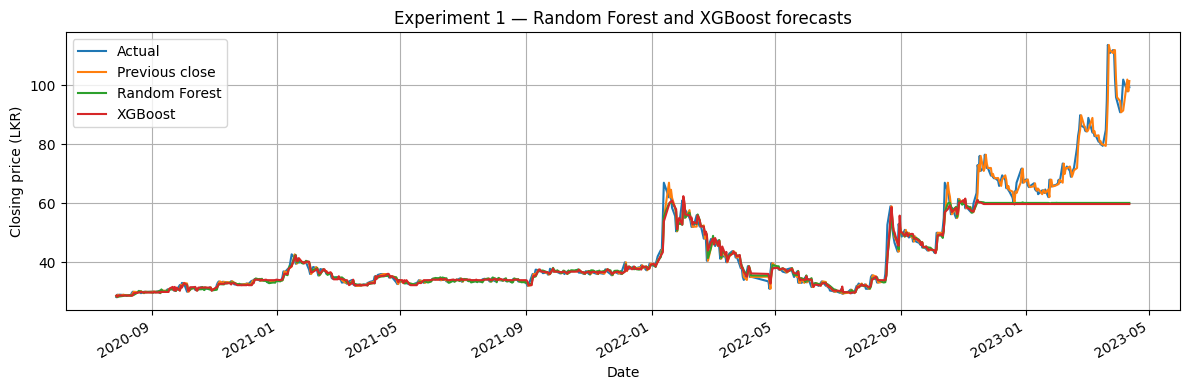

In [22]:
# Calculate both error measures in Sri Lankan rupees.
# MAE is the average size of an error. RMSE gives large errors more weight.
def score_models(predictions, model_names):
    rows = []

    for name in model_names:
        actual = predictions["Actual"]
        forecast = predictions[name]

        rows.append({
            "Model": name,
            "MAE (LKR)": mean_absolute_error(actual, forecast),
            "RMSE (LKR)": np.sqrt(mean_squared_error(actual, forecast)),
        })

    return pd.DataFrame(rows).sort_values("MAE (LKR)", ignore_index=True)


first_models = ["Previous close", "Random Forest", "XGBoost"]
display(score_models(predictions, first_models).round(3))

predictions.plot(
    x="Date",
    y=["Actual", *first_models],
    figsize=(12, 4),
    title="Experiment 1 — Random Forest and XGBoost forecasts",
    ylabel="Closing price (LKR)",
    grid=True,
)
plt.tight_layout()
plt.show()

**Interpretation of results :**


*   The baseline uses the current closing price as the forecast for the next trading day. Its MAE was LKR 1.166, meaning the predicted price differed from the actual price by about LKR 1.17 per share on average. In the graph, the baseline line follows the actual price closely because it uses the most recent close. When the price changes suddenly, the baseline reflects that change one trading day later. Even with that delay, it recorded the lowest MAE and RMSE in this experiment.
*   Random Forest averaged the predictions of multiple decision trees and produced an MAE of LKR 3.346. This means its next-day forecasts were off by about LKR 3.35 per share on average. The graph shows that the model followed many of the earlier price movements reasonably closely. However, toward the end of the test period, its forecast stayed near LKR 60 while the actual price rose above LKR 100. These large misses help explain why its RMSE reached LKR 8.344, since RMSE gives greater weight to larger errors.

*   XGBoost built its trees one after another, with each new tree learning to correct errors from the earlier trees. It produced an MAE of LKR 3.390 and an RMSE of LKR 8.461. Its forecast line often overlaps the Random Forest line, especially when both models underestimate the late price rise. Random Forest’s average error was lower by only LKR 0.044 per share, or about 4 cents. This shows that bagging and boosting performed similarly on these test dates.

*  Both forecasts stayed near LKR 60 during the late price rise, even as the actual closing price passed LKR 110. The highest closing price used as a training target was LKR 63.10. This can happen when higher prices still follow the same paths through the trained trees, so a further rise in price produces little change in the forecast.






## Experiment 2 — Stacking RF and XGBoost

Stacking gives a second model two inputs: the Random Forest forecast and the XGBoost forecast. Linear Regression learns how to combine them into one closing-price forecast.

To train the combiner fairly, we reserve the last 20% of the training period for validation. We train temporary copies of RF and XGBoost on earlier rows and ask them to forecast those validation dates. The combiner learns from these forecasts and the actual validation prices.

In [15]:
# Reserve the most recent part of the training period for stacking validation.
cut = int(len(X_train) * 0.80)

X_early = X_train.iloc[:cut]
y_early = y_train.iloc[:cut]
X_valid = X_train.iloc[cut:]
y_valid = y_train.iloc[cut:]

# Clone the model settings and train fresh copies using only earlier rows.
rf_early = clone(rf).fit(X_early, y_early)
xgb_early = clone(xgb).fit(X_early, y_early)

# Each validation row now has two forecasts made without its answer.
validation_forecasts = pd.DataFrame({
    "Random Forest": rf_early.predict(X_valid),
    "XGBoost": xgb_early.predict(X_valid),
})

# Learn how to combine the two forecasts into one price.
stack = LinearRegression()
stack.fit(validation_forecasts, y_valid)

# For the final test, use the full-training models from Experiment 1.
test_forecasts = predictions[["Random Forest", "XGBoost"]]
predictions["Stacking"] = stack.predict(test_forecasts)

# Show what goes into the stack and what comes out.
display(predictions[
    ["Date", "Random Forest", "XGBoost", "Stacking", "Actual"]
].head().round(3))

,Date,Random Forest,XGBoost,Stacking,Actual
0,2020-07-28,28.606,28.700001,26.999,28.2
1,2020-07-29,28.155,28.275000,26.167,29.0
2,2020-07-30,28.504,28.700001,26.911,28.5
3,2020-07-31,28.392,28.700001,26.815,29.0
4,2020-08-04,28.582,28.700001,26.978,28.9


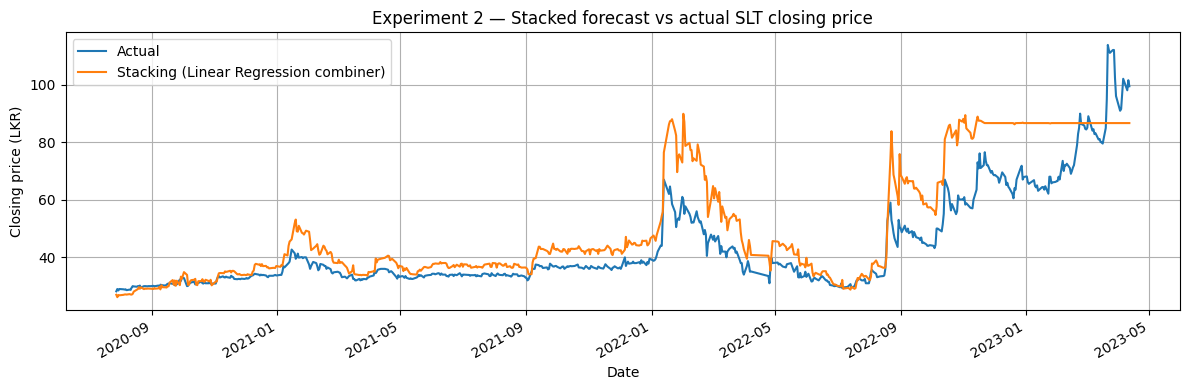

,Model,MAE (LKR),RMSE (LKR)
0,Previous close,1.166,2.173
1,Random Forest,3.346,8.344
2,XGBoost,3.390,8.461
3,Stacking (Linear Regression combiner),7.869,10.999


In [16]:
# Give the stacked forecast a clear label for the graph and table.
stack_label = "Stacking (Linear Regression combiner)"
plot_data = predictions.rename(columns={"Stacking": stack_label})

# Plot the actual closing price and the stacked forecast.
plot_data.plot(
    x="Date",
    y=["Actual", stack_label],
    figsize=(12, 4),
    title="Experiment 2 — Stacked forecast vs actual SLT closing price",
    ylabel="Closing price (LKR)",
    grid=True,
)
plt.tight_layout()
plt.show()

# Compare all four forecasts in one table.
all_models = ["Previous close", "Random Forest", "XGBoost", stack_label]
results = score_models(plot_data, all_models)
display(results.round(3))

In [23]:
# Compare the highest actual next-day close in training and validation.
print(f"Full training maximum: LKR {y_train.max():.2f}")
print(f"Stacking validation maximum: LKR {y_valid.max():.2f}")

# Show the weight that Linear Regression learned for each model.
for model, weight in zip(validation_forecasts.columns, stack.coef_):
    print(f"{model} weight: {weight:.3f}")
print(f"Intercept: {stack.intercept_:.3f}")

# See what stacking predicts if both models forecast LKR 60.
example = pd.DataFrame({"Random Forest": [60.0], "XGBoost": [60.0]})
print(f"Stacked forecast when both predict LKR 60: LKR {stack.predict(example)[0]:.2f}")

Full training maximum: LKR 63.10
Stacking validation maximum: LKR 33.90
Random Forest weight: 0.859
XGBoost weight: 1.048
Intercept: -27.629
Stacked forecast when both predict LKR 60: LKR 86.74


**Interpretation of results :**


*  Stacking (Linear Regression combiner) - Linear Regression was chosen as the stacking combiner because the target is a numerical price. It learns how much weight to give each model’s forecast when predicting the next trading day’s closing price in LKR. It gave Random Forest a weight of 0.859 and XGBoost a weight of 1.048, with an intercept of −27.629. The example above shows what this means in practice. When both models predicted LKR 60, the combined forecast was LKR 86.74. During the part of the test period when the stacked forecast stayed near LKR 87, it was too high on days when the actual price was below that level and too low when the price climbed above LKR 110. Over all 646 test days, stacking had an MAE of LKR 7.869, compared with LKR 3.346 for Random Forest and LKR 3.390 for XGBoost. Combining the forecasts more than doubled the average error in this experiment.


In [17]:
from google.colab import files

# Save actual prices and all four forecasts for the dashboard.
plot_data.to_csv("01_ensemble_predictions.csv", index=False)
files.download("01_ensemble_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

Random Forest produced slightly lower forecast errors than XGBoost. Stacking the two forecasts increased the error on the test period. The previous-close baseline achieved the lowest MAE and RMSE overall.

For this dataset and test period, using the latest closing price gave the most accurate next-day forecast among the four methods evaluated.